[01 Universal Transformer](01_universal_transformer.ipynb) · [02 Adaptive Computation Time](02_act_halting.ipynb) · [03 Recurrent depth](03_recurrent_depth.ipynb) · [04 Fixed point (DEQ)](04_deq_fixed_point.ipynb) · **05 Mixture-of-Recursions** · [06 Relaxed recursion](06_relaxed_recursion.ipynb) · [07 Scratchpad memory](07_scratchpad_memory.ipynb) · [08 Layer-sharing schedules](08_layer_sharing.ipynb)

# Looped transformers 05 - Mixture-of-Recursions: a router gives every token its own depth

In a looped transformer one shared block is applied $T$ times, and **every token pays for all $T$ passes**, even an easy one like the space after "the". *Mixture-of-Recursions* (MoR, Bae et al. 2025) adds a tiny **router** that decides, per token, how many passes it gets. Easy tokens leave early and hard tokens keep going. This notebook builds MoR from scratch in plain PyTorch: both routing styles (expert-choice and token-choice), the gated update that lets the router learn, the Switch-style load-balancing loss, a demonstration that expert-choice top-k **leaks future information** in a causal LM (and the paper's fix), the "middle-cycle" prelude/coda layout, and a gather/scatter implementation that actually skips computation. Every claim is measured on a 4-sentence toy corpus and on about 143k characters of real English (Python standard-library docstrings).

| What you will learn | Where |
|---|---|
| Why per-token depth saves compute in a looped model | 1 |
| Expert-choice routing (top-k per step, hierarchical, capacity factor) | 2, 3 |
| Token-choice routing (each token picks its depth once) | 2, 3 |
| The gated update $h \leftarrow h + g\,(f(h)-h)$ and why it gives the router a gradient | 2, 3 |
| Why expert-choice top-k breaks causality, measured, and the auxiliary-router fix | 3, 8 |
| Switch-style load balancing and what it does to the depth histogram | 8 |
| Dense masked vs gather/scatter execution, and when compute savings become wall-clock savings | 8 |
| KV-cache options for MoR (recursion-wise caching vs recursive sharing) | 9 |

**Prerequisites:** Python, basic PyTorch (tensors, `nn.Module`, autograd, an optimizer loop), a rough idea of attention. Notebook 01 of this series writes attention by hand; here we use `nn.MultiheadAttention`.

**Estimated runtime:** RUNTIME_PLACEHOLDER on 2 CPU threads.

In [1]:
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(2)          # other notebooks share this CPU; keep it polite
NOTEBOOK_START = time.time()
FAST = False                   # True only for a quick smoke test of the notebook itself


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(0)
print("torch", torch.__version__, "| threads:", torch.get_num_threads())

torch 2.13.0 | threads: 2


## 1. Intuition

Picture a team of proof-readers who all use **the same checklist** (the shared block). A plain looped model makes every word in the document go through the checklist three times. That is wasteful: "the" is fine after one read, while a rare technical word might need all three. MoR puts a **receptionist (the router)** at the door of each round. Either the receptionist picks the most promising words for the next round (**expert-choice**: "round 2 only has room for 2/3 of the words") or every word decides up front how many rounds it wants (**token-choice**).

A word that skips a round is not deleted. **Its hidden state is just frozen** and carried forward to the final (coda) layer. Following the paper's best layout, *middle-cycle* sharing, the first and last layers are ordinary unshared blocks, and only the middle block is looped:

```mermaid
flowchart TB
    X["characters x  (B, L)"] --> EMB["token + position embedding  (B, L, d)"]
    EMB --> PRE["Prelude block (own weights)"]
    PRE --> R1{"router, step 1"}
    R1 -->|"selected"| S1["Shared block, pass 1"]
    R1 -->|"not selected: state frozen"| CODA
    S1 --> R2{"router, step 2"}
    R2 -->|"selected"| S2["Shared block, pass 2 (same weights)"]
    R2 -->|"exit"| CODA
    S2 --> R3{"router, step 3"}
    R3 -->|"selected"| S3["Shared block, pass 3 (same weights)"]
    R3 -->|"exit"| CODA
    S3 --> CODA["Coda block (own weights)"]
    CODA --> HEAD["LayerNorm + LM head  ->  logits (B, L, V)"]
```

**Why prelude and coda are unshared.** The first layer turns raw embeddings into a working representation, and the last layer turns that representation into next-token logits. These are different jobs from "refine the representation", which is what the looped block repeats. In the paper's ablations, giving those two jobs their own weights (middle-cycle) beat sharing everything (cycle) or sharing in consecutive groups (sequence). We do not re-run that ablation here (notebook 08 compares sharing schedules). We simply adopt the layout.

## 2. The math

Shapes: batch $B$, sequence length $L$, model width $d$, number of recursion steps $T$, vocabulary $V$. Let $N = B\cdot L$ be the number of tokens in a batch.

**Prelude.** $h^{0} = \mathrm{Prelude}(E[x] + P) \in \mathbb{R}^{B\times L\times d}$, where $E$ is the token embedding and $P$ the learned position embedding.

**Shared step.** $f(\cdot\,;\mathcal{S})$ is the shared pre-norm transformer block. When it runs at step $t$, attention is restricted to the tokens that are *active* at that step, the set $\mathcal{S}_t$: a query at position $i$ sees key $j$ only if $j \le i$ (causal) and $j \in \mathcal{S}_t$.

**Gated update** (both routing styles), for token $i$ at step $t = 1..T$:

$$
h^{t}_i = \begin{cases} h^{t-1}_i + g_{t,i}\,\big(f(h^{t-1};\mathcal{S}_t)_i - h^{t-1}_i\big) & i \in \mathcal{S}_t \\ h^{t-1}_i & i \notin \mathcal{S}_t \end{cases}
$$

$g_{t,i}\in(0,1)$ is the router's score. Choosing *which* tokens are in $\mathcal{S}_t$ is a discrete decision with no gradient. **Multiplying the update by $g$ is what lets the loss push the router**: if the update helps token $i$, $\partial \mathcal{L}/\partial g_{t,i} < 0$, so the router learns to score it higher.

**(a) Expert-choice (EC).** At each step a router $r_t(h) = w_t^\top h + b_t$ (one scalar per token, shape $(B, L)$) scores the tokens. The gate is $g_{t,i}=\sigma(r_t(h^{t-1}_i))$. The step keeps the top-$k_t$ tokens **among those kept at the previous step** (hierarchical):

$$
\mathcal{S}_0 = \{1..L\},\qquad \mathcal{S}_t = \operatorname{TopK}_{i\in\mathcal{S}_{t-1}}\big(r_t(h^{t-1}_i),\,k_t\big),\qquad k_t = \lceil \beta_t L \rceil,\ \beta_t = \tfrac{T-t+1}{T}
$$

With $T=3$ the capacities are $\beta = (1, \tfrac23, \tfrac13)$. Every token gets one pass, 2/3 get two, and 1/3 get three. That is $\sum_t \beta_t = 2$ shared passes per token instead of 3, a **guaranteed 33% saving** in shared-block compute. The top-k is taken over the $L$ positions of one sequence, which is exactly what breaks causality (section 3.5).

**(b) Token-choice (TC).** One router reads $h^0$ once: $p_i = \mathrm{softmax}(W h^0_i) \in \mathbb{R}^{T}$, depth $D_i = \arg\max_\delta p_{i,\delta}$, gate $g_{t,i} = p_{i,D_i}$ for every step, and $i\in\mathcal{S}_t \iff D_i \ge t$. Each token's decision uses only its own (causal) state, so nothing leaks, but **nothing forces a compute budget either**.

**Load balancing (Switch Transformer style)** for TC, with $f_\delta$ the fraction of tokens routed to depth $\delta$ (a count, so no gradient) and $P_\delta$ the mean router probability for depth $\delta$:

$$
\mathcal{L}_{\text{bal}} = T\sum_{\delta=1}^{T} f_\delta P_\delta,\qquad f_\delta = \frac1N\sum_i \mathbb{1}[D_i=\delta],\qquad P_\delta=\frac1N\sum_i p_{i,\delta}
$$

It equals 1 when routing is uniform and $T$ when everything collapses onto one depth with probability 1.

**Auxiliary router loss** for EC (the causality fix used at inference): train the router's logits to *predict its own top-k decision* with binary cross-entropy, over the tokens that were candidates at step $t$:

$$
\mathcal{L}_{\text{bce}} = \frac1T\sum_{t=1}^{T} \mathrm{BCE}\big(r_t(h^{t-1}_i),\ \mathbb{1}[i\in\mathcal{S}_t]\big)_{i\in\mathcal{S}_{t-1}}
$$

At inference you then use the causal rule $i \in \mathcal{S}_t \iff i\in\mathcal{S}_{t-1} \wedge \sigma(r_t) > 0.5$, which never looks at other positions.

**Total loss:** $\mathcal{L} = \mathrm{CE} + \lambda_{\text{bal}}\mathcal{L}_{\text{bal}} + \lambda_{\text{bce}}\mathcal{L}_{\text{bce}}$. **Compute** is counted in *token-passes* through the shared block, $\sum_t |\mathcal{S}_t|$, compared with $T\cdot N$ for the full looped model.

## 3. Building blocks from scratch

### 3.1 Causal mask and the baseline pre-norm block
`nn.MultiheadAttention` takes a boolean `attn_mask` where **`True` means "this query may NOT look at this key"**. The causal mask therefore has `True` strictly above the diagonal, so position $i$ cannot see positions $j>i$. The block is the series baseline: LayerNorm, causal self-attention, residual, then LayerNorm, MLP(GELU), residual.

In [2]:
def causal_mask(length: int) -> torch.Tensor:
    """(L, L) bool, True above the diagonal = 'query i may not attend to future key j'."""
    return torch.triu(torch.ones(length, length, dtype=torch.bool), diagonal=1)


class Block(nn.Module):
    """Pre-norm transformer block: x + Attn(LN(x)), then x + MLP(LN(x))."""

    def __init__(self, d_model: int, n_heads: int, mlp_mult: int = 4) -> None:
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, mlp_mult * d_model), nn.GELU(),
                                 nn.Linear(mlp_mult * d_model, d_model))

    def forward(self, h: torch.Tensor, blocked: torch.Tensor) -> torch.Tensor:
        # blocked: (L, L) shared by the batch, or (B * n_heads, L, L) per sequence
        a = self.ln1(h)
        h = h + self.attn(a, a, a, attn_mask=blocked, need_weights=False)[0]
        h = h + self.mlp(self.ln2(h))
        return h


print(causal_mask(5).int())

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)


In [3]:
set_seed(1)
blk = Block(64, 4).eval()
h_toy = torch.randn(2, 10, 64)
out = blk(h_toy, causal_mask(10))
assert out.shape == h_toy.shape

# causality check: perturb position 6, outputs at positions 0..5 must not move
h_perturbed = h_toy.clone()
h_perturbed[:, 6] += 1.0
out_perturbed = blk(h_perturbed, causal_mask(10))
change = (out - out_perturbed).abs().amax(dim=(0, 2))
print("max change per position:", [f"{c:.1e}" for c in change.tolist()])
assert change[:6].max() < 1e-6 and change[6] > 1e-3
print("OK: block is causal")

max change per position: ['0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '1.0e+00', '2.4e-07', '2.4e-07', '2.4e-07']
OK: block is causal


### 3.2 Attention restricted to active tokens

During recursion step $t$ only the tokens in $\mathcal{S}_t$ are processed. In the paper's default *recursion-wise* KV caching, an active token also **only attends to other tokens active at that step** (inactive tokens produce no keys/values at that depth). The dense way to express this is a per-sequence mask: key $j$ is blocked if it is in the future **or not selected**. One subtlety: an unselected query would then have *every* key blocked, softmax over all $-\infty$ gives NaN, and NaN times a zero gate is still NaN. So **every query is always allowed to see itself**. Those rows are computed and thrown away.

In [4]:
def routed_blocked_mask(selected: torch.Tensor, n_heads: int) -> torch.Tensor:
    """selected: (B, L) bool. Returns (B * n_heads, L, L) bool for nn.MultiheadAttention."""
    batch, length = selected.shape
    future = causal_mask(length).unsqueeze(0)                      # (1, L, L)
    key_inactive = ~selected.unsqueeze(1)                          # (B, 1, L): column j blocked if j not selected
    blocked = future | key_inactive                                # (B, L, L)
    eye = torch.eye(length, dtype=torch.bool).unsqueeze(0)
    blocked = blocked & ~eye                                       # always allow self -> no all-masked rows
    return blocked.repeat_interleave(n_heads, dim=0)               # layout expected by MHA: index b * H + head


sel_demo = torch.tensor([[True, False, True, True, False]])
print(routed_blocked_mask(sel_demo, n_heads=1)[0].int())
print("row 3 (selected) may attend to keys", (~routed_blocked_mask(sel_demo, 1)[0, 3]).nonzero().flatten().tolist())
assert (~routed_blocked_mask(sel_demo, 1)[0, 3]).nonzero().flatten().tolist() == [0, 2, 3]

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 1, 0, 1, 1],
        [0, 1, 0, 0, 1],
        [0, 1, 0, 0, 0]], dtype=torch.int32)
row 3 (selected) may attend to keys [0, 2, 3]


### 3.3 One recursion step, two implementations

* **Dense masked**: run the block on all $L$ tokens with the routed mask, then gate the update. Simple, but **it does exactly the same FLOPs as the full model**, so the saving exists only on paper.
* **Gather/scatter**: copy out the $k$ selected tokens (in time order), run the block on a length-$k$ sequence with an ordinary causal mask, and write the results back. This really does less work. Attention cost drops by $(k/L)^2$ and the MLP by $k/L$.

The two must give the same numbers. That is our "same equation, two ways" check. Note the `.sort()`: the top-k indices come out ordered by score, and if we did not put them back in time order the compacted causal mask would let tokens see the future.

In [5]:
def recursion_step_dense(block: Block, h: torch.Tensor, selected: torch.Tensor,
                         gate: torch.Tensor, n_heads: int) -> torch.Tensor:
    """h <- h + g * (f(h) - h) for selected tokens; others unchanged. h: (B, L, d)."""
    delta = block(h, routed_blocked_mask(selected, n_heads)) - h
    weight = (gate * selected.float()).unsqueeze(-1)              # (B, L, 1); 0 for unselected tokens
    return h + weight * delta


def recursion_step_gather(block: Block, h: torch.Tensor, sel_idx: torch.Tensor,
                          gate: torch.Tensor) -> torch.Tensor:
    """Same update, but the block only sees the k selected tokens. sel_idx: (B, k) sorted positions."""
    batch, k = sel_idx.shape
    d_model = h.shape[-1]
    idx3 = sel_idx.unsqueeze(-1).expand(batch, k, d_model)
    h_sel = h.gather(1, idx3)                                      # (B, k, d) compacted sequence
    out = block(h_sel, causal_mask(k))                             # ordinary causal attention over k tokens
    g = gate.gather(1, sel_idx).unsqueeze(-1)                      # (B, k, 1)
    return h.scatter(1, idx3, h_sel + g * (out - h_sel))           # write back; other rows untouched

### 3.4 The two routers

**Expert-choice selection** picks the top-$k$ among the still-active tokens (inactive ones get score $-\infty$, which makes the routing hierarchical). **Token-choice** picks a depth per token from a softmax, and its gate is the probability of the chosen depth.

In [6]:
def expert_choice_select(scores: torch.Tensor, active: torch.Tensor, k: int) -> tuple[torch.Tensor, torch.Tensor]:
    """scores, active: (B, L). Keep the k highest-scoring ACTIVE tokens per sequence.
    Returns a (B, L) bool mask and (B, k) indices sorted by position."""
    masked = scores.masked_fill(~active, float("-inf"))            # hierarchical: only previous survivors compete
    top = masked.topk(k, dim=-1).indices
    sel_idx = top.sort(dim=-1).values                              # time order, required for causal attention
    selected = torch.zeros_like(active)
    selected.scatter_(1, sel_idx, True)
    return selected, sel_idx


def token_choice_route(router_logits: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """router_logits: (B, L, T). Returns depth (B, L) in 1..T, gate (B, L), probs (B, L, T)."""
    probs = router_logits.softmax(dim=-1)
    choice = probs.argmax(dim=-1)                                  # 0..T-1 (discrete, no gradient)
    gate = probs.gather(-1, choice.unsqueeze(-1)).squeeze(-1)      # differentiable path to the router
    return choice + 1, gate, probs


def balance_loss(probs: torch.Tensor, depth: torch.Tensor, n_depths: int) -> torch.Tensor:
    """Switch-style: T * sum_d f_d * P_d. f_d = fraction of tokens at depth d, P_d = mean prob of d."""
    f = F.one_hot(depth.flatten() - 1, n_depths).float().mean(dim=0)   # (T,), counts -> no gradient
    p_mean = probs.reshape(-1, n_depths).mean(dim=0)                     # (T,), has gradient
    return n_depths * (f * p_mean).sum()

In [7]:
set_seed(2)
B_, L_, d_, H_ = 3, 12, 64, 4
h_demo = torch.randn(B_, L_, d_)
scores_demo = torch.randn(B_, L_)
gate_demo = torch.sigmoid(scores_demo)

# --- hierarchical expert choice over T=3 steps with capacities 1, 2/3, 1/3
active = torch.ones(B_, L_, dtype=torch.bool)
for t, beta in enumerate([1.0, 2 / 3, 1 / 3]):
    k = math.ceil(beta * L_)
    step_scores = torch.randn(B_, L_)
    selected, sel_idx = expert_choice_select(step_scores, active, k)
    assert selected.sum(dim=1).eq(k).all()
    assert (selected & ~active).sum() == 0, "a token skipped at step t-1 came back"
    assert (sel_idx[:, 1:] > sel_idx[:, :-1]).all(), "indices must be in time order"
    print(f"step {t + 1}: k={k:2d}  sequence 0 keeps positions {sel_idx[0].tolist()}")
    active = selected

# --- dense and gather give the same numbers
blk.eval()
selected, sel_idx = expert_choice_select(scores_demo, torch.ones(B_, L_, dtype=torch.bool), 5)
with torch.no_grad():
    out_dense = recursion_step_dense(blk, h_demo, selected, gate_demo, H_)
    out_gather = recursion_step_gather(blk, h_demo, sel_idx, gate_demo)
max_diff = (out_dense - out_gather).abs().max().item()
print(f"dense vs gather max |diff| = {max_diff:.2e}")
assert max_diff < 1e-5
assert torch.equal(out_dense[~selected], h_demo[~selected]), "unselected tokens must keep their state"

# --- token choice + balance loss sanity values
uniform_probs = torch.full((1, 6, 3), 1 / 3)
balanced_depth = torch.tensor([[1, 2, 3, 1, 2, 3]])
collapsed_probs = F.one_hot(torch.zeros(1, 6, dtype=torch.long), 3).float()
collapsed_depth = torch.ones(1, 6, dtype=torch.long)
print("balance loss uniform  :", balance_loss(uniform_probs, balanced_depth, 3).item())
print("balance loss collapsed:", balance_loss(collapsed_probs, collapsed_depth, 3).item())
assert abs(balance_loss(uniform_probs, balanced_depth, 3).item() - 1.0) < 1e-6
assert abs(balance_loss(collapsed_probs, collapsed_depth, 3).item() - 3.0) < 1e-6

# second implementation of f_d with bincount must agree with the one_hot version
logits_demo = torch.randn(B_, L_, 3)
depth_tc, gate_tc, probs_tc = token_choice_route(logits_demo)
f_bincount = torch.bincount(depth_tc.flatten() - 1, minlength=3).float() / depth_tc.numel()
manual = 3 * (f_bincount * probs_tc.reshape(-1, 3).mean(0)).sum()
assert torch.allclose(manual, balance_loss(probs_tc, depth_tc, 3))
print("token-choice depths, sequence 0:", depth_tc[0].tolist())

step 1: k=12  sequence 0 keeps positions [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
step 2: k= 8  sequence 0 keeps positions [1, 2, 3, 4, 6, 8, 9, 10]
step 3: k= 4  sequence 0 keeps positions [1, 6, 9, 10]
dense vs gather max |diff| = 2.38e-07
balance loss uniform  : 1.0000001192092896
balance loss collapsed: 3.0
token-choice depths, sequence 0: [1, 1, 3, 3, 2, 2, 2, 2, 1, 1, 2, 1]


### 3.5 Why expert-choice top-k is not causal

Top-$k$ is a *competition across positions*: whether token 3 survives depends on whether tokens 4, 5, ... scored higher. In a causal LM position 3 must not depend on later tokens at all. Below, the scores are computed per token (a plain linear router, causal by itself), and we change **only the last token's score**. If the last token jumps into the top-k, some earlier token is pushed out, and that earlier token's routing changed because of the future. Token-choice has no competition, so it cannot leak.

In [8]:
scores_now = torch.tensor([[0.9, 0.1, 0.5, 0.7, 0.2, 0.3]])        # 6 positions, keep k = 3
scores_future_changed = scores_now.clone()
scores_future_changed[0, 5] = 2.0                                   # only the LAST (future) token differs
everyone = torch.ones(1, 6, dtype=torch.bool)
sel_a, _ = expert_choice_select(scores_now, everyone, 3)
sel_b, _ = expert_choice_select(scores_future_changed, everyone, 3)
print("selected before:", sel_a.int().tolist()[0])
print("selected after :", sel_b.int().tolist()[0])
earlier_changed = (sel_a[0, :5] != sel_b[0, :5]).nonzero().flatten().tolist()
print("earlier positions whose routing changed because of position 5:", earlier_changed)
assert len(earlier_changed) > 0, "expected expert-choice to leak"

selected before: [1, 0, 1, 1, 0, 0]
selected after : [1, 0, 0, 1, 0, 1]
earlier positions whose routing changed because of position 5: [2]


**How the paper handles it.** Training uses top-k (it gives an exact compute budget, and the leak is a train-time convenience). For inference, where future tokens do not exist yet, the paper gives two options: (i) an **auxiliary router** trained to predict the top-k decision from the token's own state, or (ii) an **auxiliary loss** on the main router (BCE against the top-k selection) so its sigmoid outputs become usable with a fixed threshold. We implement option (ii): train with top-k plus $\mathcal{L}_{\text{bce}}$, then evaluate both with top-k (leaky) and with the causal threshold rule $\sigma(r)>0.5$. Section 8 measures both the leak and the cost of removing it.

## 4. The full model

`LoopedLM` covers all variants with one class:
* `routing="none"`: the plain looped baseline. Prelude, then the shared block applied $T$ times to every token, then coda.
* `routing="expert"`: one linear router per step, capacities $\beta_t$, top-k (training) or threshold (causal inference), optional gather/scatter execution.
* `routing="token"`: one linear router on the prelude output that picks depth $1..T$.

The only extra parameters MoR adds are the routers: $T(d+1)$ for expert-choice and $(d+1)T$ for token-choice. That is 195 parameters at $d=64$, about 0.1% of the model.

In [9]:
class LoopedLM(nn.Module):
    """Prelude block -> shared block looped T times (optionally routed per token) -> coda block -> LM head."""

    def __init__(self, vocab_size: int, d_model: int = 64, n_heads: int = 4, n_steps: int = 3,
                 max_len: int = 64, routing: str = "none",
                 capacities: tuple[float, ...] | None = None) -> None:
        super().__init__()
        assert routing in ("none", "expert", "token")
        self.T, self.routing, self.n_heads = n_steps, routing, n_heads
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.prelude = Block(d_model, n_heads)        # unshared first layer (middle-cycle)
        self.shared = Block(d_model, n_heads)         # the ONE block that is looped
        self.coda = Block(d_model, n_heads)           # unshared last layer
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)
        if routing == "expert":
            default = tuple((n_steps - t) / n_steps for t in range(n_steps))     # 1, 2/3, 1/3 for T=3
            self.capacities = capacities if capacities is not None else default
            self.routers = nn.ModuleList([nn.Linear(d_model, 1) for _ in range(n_steps)])
        if routing == "token":
            self.router = nn.Linear(d_model, n_steps)

    def _expert_choice(self, h: torch.Tensor, mode: str, impl: str):
        batch, length, _ = h.shape
        active = torch.ones(batch, length, dtype=torch.bool)
        depth = torch.zeros(batch, length, dtype=torch.long)
        bce_terms = []
        for t in range(self.T):
            logit = self.routers[t](h).squeeze(-1)                       # (B, L) router logits
            gate = torch.sigmoid(logit)
            if mode == "topk":                                           # training-time rule (looks at all positions)
                k = max(1, math.ceil(self.capacities[t] * length - 1e-9))
                selected, sel_idx = expert_choice_select(logit, active, k)
                target = selected.float()
                bce_terms.append(F.binary_cross_entropy_with_logits(logit[active], target[active]))
            elif mode == "threshold":                                    # causal inference rule
                selected, sel_idx = active & (gate > 0.5), None
            else:
                raise ValueError(mode)
            if impl == "gather" and sel_idx is not None:
                h = recursion_step_gather(self.shared, h, sel_idx, gate)
            else:
                h = recursion_step_dense(self.shared, h, selected, gate, self.n_heads)
            depth = depth + selected.long()
            active = selected
        aux_bce = torch.stack(bce_terms).mean() if bce_terms else h.new_zeros(())
        return h, depth, aux_bce

    def _token_choice(self, h: torch.Tensor):
        depth, gate, probs = token_choice_route(self.router(h))         # decided once, from the prelude output
        for t in range(self.T):
            selected = depth > t                                         # tokens that still want step t+1
            h = recursion_step_dense(self.shared, h, selected, gate, self.n_heads)
        return h, depth, balance_loss(probs, depth, self.T)

    def forward(self, idx: torch.Tensor, mode: str = "topk", impl: str = "dense"):
        batch, length = idx.shape
        positions = torch.arange(length)
        h = self.tok_emb(idx) + self.pos_emb(positions)                 # (B, L, d)
        h = self.prelude(h, causal_mask(length))
        zero = h.new_zeros(())
        aux_balance, aux_bce = zero, zero
        if self.routing == "none":
            for _ in range(self.T):
                h = self.shared(h, causal_mask(length))                  # every token, every pass
            depth = torch.full((batch, length), self.T, dtype=torch.long)
        elif self.routing == "expert":
            h, depth, aux_bce = self._expert_choice(h, mode, impl)
        else:
            h, depth, aux_balance = self._token_choice(h)
        h = self.coda(h, causal_mask(length))
        logits = self.head(self.ln_f(h))                                # (B, L, V)
        return logits, {"depth": depth, "aux_balance": aux_balance, "aux_bce": aux_bce}


def n_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())

In [10]:
set_seed(3)
V, CTX = 100, 64          # demo values; section 5 replaces V with the real tokenizer's vocabulary size
x_check = torch.randint(1, V, (4, CTX))
y_check = torch.randint(1, V, (4, CTX))
models_check = {
    "looped T=3": LoopedLM(V, routing="none", n_steps=3),
    "MoR expert-choice": LoopedLM(V, routing="expert", n_steps=3),
    "MoR token-choice": LoopedLM(V, routing="token", n_steps=3),
}
for name, m in models_check.items():
    logits, info = m(x_check)
    assert logits.shape == (4, CTX, V) and info["depth"].shape == (4, CTX)
    loss = F.cross_entropy(logits.reshape(-1, V), y_check.reshape(-1)) + info["aux_balance"] + info["aux_bce"]
    loss.backward()
    if m.routing == "expert":
        g = sum(r.weight.grad.abs().sum().item() for r in m.routers)
    elif m.routing == "token":
        g = m.router.weight.grad.abs().sum().item()
    else:
        g = float("nan")
    print(f"{name:18s} logits {tuple(logits.shape)} | mean depth {info['depth'].float().mean():.2f} | "
          f"router grad |sum| {g:.3e}")
    if m.routing != "none":
        assert g > 0, "router receives no gradient"

# gradient reaches the router through the GATE only (no aux losses): check for expert choice
m = models_check["MoR expert-choice"]
m.zero_grad()
logits, info = m(x_check)
F.cross_entropy(logits.reshape(-1, V), y_check.reshape(-1)).backward()
assert m.routers[2].weight.grad.abs().sum() > 0
print("OK: CE alone gives the step-3 router a gradient via the gate")

# dense and gather forward passes of the whole model agree
m.eval()
with torch.no_grad():
    a, _ = m(x_check, impl="dense")
    b, _ = m(x_check, impl="gather")
print(f"full model dense vs gather max |diff| = {(a - b).abs().max():.2e}")
assert (a - b).abs().max() < 1e-4
m.train()

looped T=3         logits (4, 64, 100) | mean depth 3.00 | router grad |sum| nan
MoR expert-choice  logits (4, 64, 100) | mean depth 2.02 | router grad |sum| 3.726e+00
MoR token-choice   logits (4, 64, 100) | mean depth 2.09 | router grad |sum| 9.174e-01
OK: CE alone gives the step-3 router a gradient via the gate
full model dense vs gather max |diff| = 0.00e+00


LoopedLM(
  (tok_emb): Embedding(100, 64)
  (pos_emb): Embedding(64, 64)
  (prelude): Block(
    (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
    )
    (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    (mlp): Sequential(
      (0): Linear(in_features=64, out_features=256, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=256, out_features=64, bias=True)
    )
  )
  (shared): Block(
    (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
    )
    (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    (mlp): Sequential(
      (0): Linear(in_features=64, out_features=256, bias=True)
      (1): GELU(approximate='none')
      (

In [11]:
print(f"(vocab {V} for this table; d=64, 4 heads, MLP 4x)")
print(f"{'model':28s} {'params':>8s} {'unique blocks':>13s} {'shared passes/token':>20s} {'block passes/token':>19s}")
rows = [("non-looped, 1 block each", 3, 1, "routing none, T=1"),
        ("looped T=2 (full)", 3, 2, "none"), ("looped T=3 (full)", 3, 3, "none"),
        ("MoR expert-choice T=3", 3, 2, "expert"), ("MoR token-choice T=3", 3, None, "token")]
for name, blocks, shared_passes, kind in rows:
    if kind == "expert":
        mm = LoopedLM(V, routing="expert", n_steps=3)
    elif kind == "token":
        mm = LoopedLM(V, routing="token", n_steps=3)
    else:
        mm = LoopedLM(V, routing="none", n_steps=shared_passes)
    sp = "router-decided" if shared_passes is None else f"{shared_passes:.2f}"
    bp = "2 + router" if shared_passes is None else f"{2 + shared_passes:.2f}"
    print(f"{name:28s} {n_params(mm):8,d} {blocks:13d} {sp:>20s} {bp:>19s}")

(vocab 100 for this table; d=64, 4 heads, MLP 4x)
model                          params unique blocks  shared passes/token  block passes/token
non-looped, 1 block each      167,076             3                 1.00                3.00
looped T=2 (full)             167,076             3                 2.00                4.00
looped T=3 (full)             167,076             3                 3.00                5.00
MoR expert-choice T=3         167,271             3                 2.00                4.00
MoR token-choice T=3          167,271             3       router-decided          2 + router


**Parameters are (almost) constant while compute changes.** All looped variants have the same three unique blocks. Only the number of times the middle block runs per token differs. Expert-choice fixes that number at 2.0 by construction. Token-choice leaves it to the router, so it has to be measured.

## 5. Data

Two corpora, shared by all eight notebooks:
* **Toy corpus**: four 48-character sentences with two genuine choice points (*model/robot* and *write/spell*). Small enough to see every routing decision.
* **Docstring corpus**: docstrings of 30 standard-library modules. This is real English, it ships with Python, and it needs no download. Split 90/10 by position. We train on random 64-character windows and report validation **bits per character** (bpc = cross-entropy / ln 2).

In [12]:
TOY_CORPUS = [
    "the tiny model learned to write this sentence :)",
    "the tiny robot learned to write this sentence :)",
    "the tiny model learned to spell this sentence :)",
    "the tiny robot learned to spell this sentence :)",
]  # 48 chars each; two genuine choice points: model/robot and write/spell


def docstring_corpus() -> str:
    """Real English text that ships with Python: docstrings of standard-library modules."""
    import importlib, inspect, re
    mods = ["collections", "itertools", "functools", "json", "re", "string", "textwrap", "pathlib",
            "datetime", "statistics", "random", "heapq", "bisect", "typing", "dataclasses", "argparse",
            "logging", "enum", "fractions", "decimal", "csv", "shutil", "tempfile", "contextlib", "abc",
            "copy", "pprint", "difflib", "calendar", "zipfile"]
    docs = []
    for m in mods:
        for _, obj in inspect.getmembers(importlib.import_module(m)):
            d = inspect.getdoc(obj)
            if d and len(d) > 60 and (inspect.isfunction(obj) or inspect.isclass(obj) or inspect.ismethod(obj)):
                docs.append(d)
    return re.sub(r"\s+", " ", " ".join(dict.fromkeys(docs)))


doc_text = docstring_corpus()
assert all(len(s) == 48 for s in TOY_CORPUS)
print(f"docstring corpus: {len(doc_text):,} characters, {len(set(doc_text))} distinct")
print(repr(doc_text[:200]))

docstring corpus: 142,997 characters, 98 distinct
'A ChainMap groups multiple dicts (or other mappings) together to create a single, updateable view. The underlying mappings are stored in a list. That list is public and can be accessed or updated usin'


In [13]:
class CharTokenizer:
    """Character-level tokenizer. Id 0 is a beginning-of-sequence marker (shown as '^')."""

    BOS = 0

    def __init__(self, text: str) -> None:
        self.chars = sorted(set(text))
        self.stoi = {ch: i + 1 for i, ch in enumerate(self.chars)}
        self.itos = {i: ch for ch, i in self.stoi.items()}
        self.itos[self.BOS] = "^"
        self.vocab_size = len(self.chars) + 1

    def encode(self, text: str) -> torch.Tensor:
        return torch.tensor([self.stoi[ch] for ch in text], dtype=torch.long)

    def decode(self, ids) -> str:
        return "".join(self.itos[int(i)] for i in ids)


tok = CharTokenizer(doc_text + "".join(TOY_CORPUS))
assert tok.decode(tok.encode(TOY_CORPUS[0])) == TOY_CORPUS[0]
V = tok.vocab_size
print("vocab size:", V)

CTX = 64                                    # context length for the docstring corpus
doc_ids = tok.encode(doc_text)
n_train = int(0.9 * len(doc_ids))
train_ids, val_ids = doc_ids[:n_train], doc_ids[n_train:]


def doc_batch(batch_size: int, gen: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    """Random 64-char training windows; y is x shifted left by one (next-character targets)."""
    starts = torch.randint(0, len(train_ids) - CTX - 1, (batch_size,), generator=gen).tolist()
    x = torch.stack([train_ids[s:s + CTX] for s in starts])
    y = torch.stack([train_ids[s + 1:s + CTX + 1] for s in starts])
    return x, y


# a FIXED validation set of non-overlapping windows, identical for every model
n_val_windows = min(256, (len(val_ids) - 1) // CTX)
val_x = torch.stack([val_ids[i * CTX:(i + 1) * CTX] for i in range(n_val_windows)])
val_y = torch.stack([val_ids[i * CTX + 1:(i + 1) * CTX + 1] for i in range(n_val_windows)])

# toy corpus: input = BOS + sentence[:-1], target = sentence (predict every character)
toy_y = torch.stack([tok.encode(s) for s in TOY_CORPUS])                              # (4, 48)
toy_x = torch.cat([torch.full((4, 1), CharTokenizer.BOS), toy_y[:, :-1]], dim=1)       # (4, 48)


def toy_batch(batch_size: int, gen: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    rows = torch.randint(0, 4, (batch_size,), generator=gen)
    return toy_x[rows], toy_y[rows]


print(f"train chars {len(train_ids):,} | val chars {len(val_ids):,} | val windows {tuple(val_x.shape)} "
      f"= {val_x.numel():,} scored characters")
print("toy x[0]:", tok.decode(toy_x[0]))
print("toy y[0]:", tok.decode(toy_y[0]))

vocab size: 99
train chars 128,697 | val chars 14,300 | val windows (223, 64) = 14,272 scored characters
toy x[0]: ^the tiny model learned to write this sentence :


toy y[0]:

 the tiny model learned to write this sentence :)


## 6. Training loop

Written out explicitly: AdamW, linear warm-up then cosine decay, gradient clipping. Each model gets **the same seeded stream of batches** (its own `torch.Generator`), so differences between models are not caused by different data order. Aux-loss weights: $\lambda_{\text{bal}}=0.1$, $\lambda_{\text{bce}}=0.1$.

In [14]:
STEPS_TOY = 400
STEPS_DOC = 1200
BATCH = 32
LR = 3e-3


def train_model(model: LoopedLM, batch_fn, steps: int, batch_size: int = BATCH, lr: float = LR,
                balance_coef: float = 0.0, bce_coef: float = 0.0, seed: int = 0,
                log_every: int = 25) -> dict:
    gen = torch.Generator().manual_seed(seed)                  # same batches for every model
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    warmup = max(1, steps // 20)
    hist = {"step": [], "ce": [], "passes": [], "balance": []}
    model.train()
    t0 = time.time()
    for step in range(steps):
        lr_now = lr * min(1.0, (step + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * step / steps))
        for group in opt.param_groups:
            group["lr"] = lr_now
        x, y = batch_fn(batch_size, gen)
        logits, info = model(x)
        ce = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1))
        loss = ce + balance_coef * info["aux_balance"] + bce_coef * info["aux_bce"]
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if step % log_every == 0 or step == steps - 1:
            hist["step"].append(step)
            hist["ce"].append(ce.item())
            hist["passes"].append(info["depth"].float().mean().item() / model.T)   # fraction of full depth
            hist["balance"].append(float(info["aux_balance"]))
    hist["seconds"] = time.time() - t0
    return hist


@torch.no_grad()
def evaluate(model: LoopedLM, x_all: torch.Tensor, y_all: torch.Tensor, mode: str = "topk",
             batch_size: int = 64) -> dict:
    """Validation bits/char, fraction of shared-block token-passes used, and the depth histogram."""
    model.eval()
    total_ce, total_n = 0.0, 0
    depth_counts = torch.zeros(model.T + 1)
    for i in range(0, len(x_all), batch_size):
        logits, info = model(x_all[i:i + batch_size], mode=mode)
        y = y_all[i:i + batch_size]
        total_ce += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1), reduction="sum").item()
        total_n += y.numel()
        depth_counts += torch.bincount(info["depth"].flatten(), minlength=model.T + 1).float()
    model.train()
    depth_frac = depth_counts / depth_counts.sum()
    mean_depth = (depth_frac * torch.arange(model.T + 1)).sum().item()
    return {"bpc": total_ce / total_n / math.log(2), "passes": mean_depth / model.T,
            "mean_depth": mean_depth, "depth_hist": depth_frac.numpy()}

### 6.1 Toy corpus: an expert-choice and a token-choice MoR
Both have $T=3$ and $d=64$. Sequences are 48 characters, so the expert-choice capacities are $k = 48, 32, 16$.

In [15]:
toy_models, toy_hist = {}, {}
for name, routing, bal, bce in [("expert-choice", "expert", 0.0, 0.1), ("token-choice", "token", 0.1, 0.0)]:
    set_seed(10)
    toy_models[name] = LoopedLM(V, d_model=64, n_steps=3, routing=routing, max_len=64)
    toy_hist[name] = train_model(toy_models[name], toy_batch, STEPS_TOY, batch_size=16,
                                 balance_coef=bal, bce_coef=bce, seed=10)
    ev = evaluate(toy_models[name], toy_x, toy_y)
    print(f"{name:14s} final train CE {toy_hist[name]['ce'][-1]:.3f} nats | toy bpc {ev['bpc']:.3f} | "
          f"shared passes {ev['passes']:.2f} of full | {toy_hist[name]['seconds']:.1f}s")

# floor: two binary choices per sentence = 2 bits over 48 chars
print(f"irreducible toy entropy = 2 bits / 48 chars = {2 / 48:.4f} bpc")

expert-choice  final train CE 0.017 nats | toy bpc 0.024 | shared passes 0.67 of full | 16.0s


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_25454/2601638283.py:32: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:823.)
  hist["balance"].append(float(info["aux_balance"]))


token-choice   final train CE 0.031 nats | toy bpc 0.045 | shared passes 0.66 of full | 14.5s
irreducible toy entropy = 2 bits / 48 chars = 0.0417 bpc


### 6.2 Docstring corpus: five models at matched parameters
| name | routing | shared passes per token |
|---|---|---|
| looped T=3 (full) | none | 3 |
| looped T=2 (full) | none | 2 (the **compute-matched** baseline for MoR) |
| MoR expert-choice | top-k, capacities 1, 2/3, 1/3, plus BCE aux | 2 by construction |
| MoR token-choice + balance | softmax depth, $\lambda_{\text{bal}}=0.1$ | measured |
| MoR token-choice, no balance | softmax depth, no aux | measured |

In [16]:
doc_configs = {
    "looped T=3 (full)":        dict(routing="none", n_steps=3, bal=0.0, bce=0.0),
    "looped T=2 (full)":        dict(routing="none", n_steps=2, bal=0.0, bce=0.0),
    "MoR expert-choice":        dict(routing="expert", n_steps=3, bal=0.0, bce=0.1),
    "MoR token-choice + bal":   dict(routing="token", n_steps=3, bal=0.1, bce=0.0),
    "MoR token-choice, no bal": dict(routing="token", n_steps=3, bal=0.0, bce=0.0),
}
doc_models, doc_hist = {}, {}
for name, cfg in doc_configs.items():
    set_seed(20)                                             # same init seed for every model
    doc_models[name] = LoopedLM(V, d_model=64, n_steps=cfg["n_steps"], routing=cfg["routing"], max_len=CTX)
    doc_hist[name] = train_model(doc_models[name], doc_batch, STEPS_DOC,
                                 balance_coef=cfg["bal"], bce_coef=cfg["bce"], seed=20)
    print(f"{name:26s} {n_params(doc_models[name]):7,d} params | {doc_hist[name]['seconds']:6.1f}s train | "
          f"last train CE {doc_hist[name]['ce'][-1]:.3f}")

looped T=3 (full)          166,947 params |  105.2s train | last train CE 1.379


looped T=2 (full)          166,947 params |  144.4s train | last train CE 1.396


MoR expert-choice          167,142 params |  193.4s train | last train CE 1.429


MoR token-choice + bal     167,142 params |  187.1s train | last train CE 1.441


MoR token-choice, no bal   167,142 params |  197.6s train | last train CE 1.441


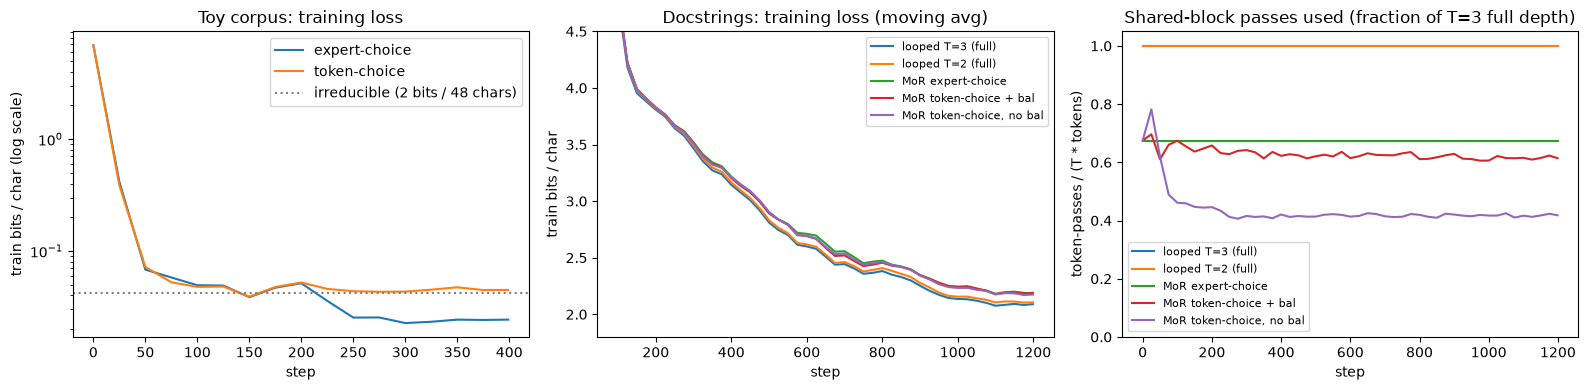

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, hist in toy_hist.items():
    axes[0].plot(hist["step"], np.array(hist["ce"]) / math.log(2), label=name)
axes[0].axhline(2 / 48, color="gray", ls=":", label="irreducible (2 bits / 48 chars)")
axes[0].set_yscale("log")
axes[0].set_title("Toy corpus: training loss")
axes[0].set_xlabel("step")
axes[0].set_ylabel("train bits / char (log scale)")
axes[0].legend()

for name, hist in doc_hist.items():
    ce = np.array(hist["ce"]) / math.log(2)
    window = min(5, len(ce))
    smooth = np.convolve(ce, np.ones(window) / window, mode="valid")    # moving average of the logged points
    axes[1].plot(hist["step"][window - 1:], smooth, label=name)
    axes[2].plot(hist["step"], hist["passes"], label=name)
axes[1].set_title("Docstrings: training loss (moving avg)")
axes[1].set_xlabel("step")
axes[1].set_ylabel("train bits / char")
axes[1].set_ylim(1.8, 4.5)
axes[1].legend(fontsize=8)
axes[2].set_title("Shared-block passes used (fraction of T=3 full depth)")
axes[2].set_xlabel("step")
axes[2].set_ylabel("token-passes / (T * tokens)")
axes[2].set_ylim(0, 1.05)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

TODO_CONCL_TRAIN

## 7. Look inside: who gets how much depth?

### 7.1 Toy sentences
Each cell is one target character. The colour is how many shared-block passes the model spent before predicting it (1 to 3). The two choice points are outlined in red: the first letter of *model/robot* and the first letter of *write/spell*.

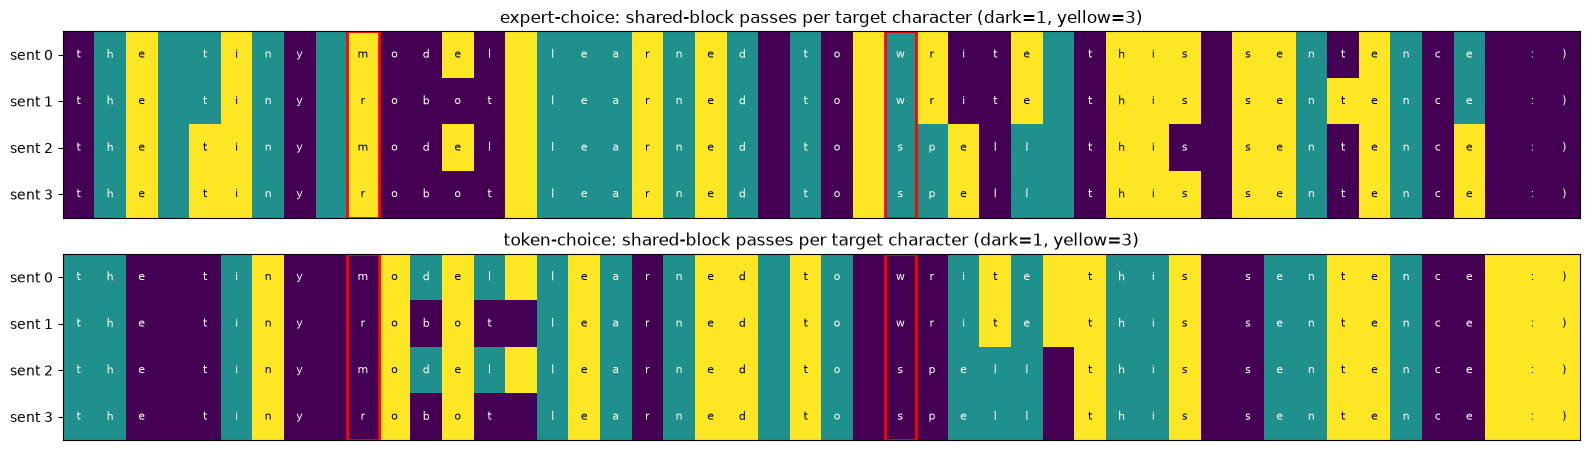

expert-choice  mean depth at choice points 2.50 | elsewhere 1.98 | depth histogram (1,2,3): [64, 64, 64]
token-choice   mean depth at choice points 1.00 | elsewhere 2.03 | depth histogram (1,2,3): [64, 66, 62]


In [18]:
choice_positions = [TOY_CORPUS[0].index("model"), TOY_CORPUS[0].index("write")]
fig, axes = plt.subplots(2, 1, figsize=(16, 4.6))
toy_depths = {}
for ax, (name, model) in zip(axes, toy_models.items()):
    model.eval()
    with torch.no_grad():
        _, info = model(toy_x)
    model.train()
    depth = info["depth"].numpy()
    toy_depths[name] = depth
    ax.imshow(depth, cmap="viridis", vmin=1, vmax=3, aspect="auto")
    for r in range(4):
        for c in range(48):
            ax.text(c, r, TOY_CORPUS[r][c], ha="center", va="center", fontsize=8,
                    color="white" if depth[r, c] < 2.5 else "black")
    for c in choice_positions:
        ax.add_patch(plt.Rectangle((c - 0.5, -0.5), 1, 4, fill=False, ec="red", lw=2))
    ax.set_yticks(range(4))
    ax.set_yticklabels([f"sent {i}" for i in range(4)])
    ax.set_xticks([])
    ax.set_title(f"{name}: shared-block passes per target character (dark=1, yellow=3)")
plt.tight_layout()
plt.show()

for name, depth in toy_depths.items():
    at_choice = depth[:, choice_positions].mean()
    print(f"{name:14s} mean depth at choice points {at_choice:.2f} | elsewhere "
          f"{np.delete(depth, choice_positions, axis=1).mean():.2f} | depth histogram (1,2,3): "
          f"{[int((depth == k).sum()) for k in (1, 2, 3)]}")

TODO_CONCL_TOY

### 7.2 Docstring text
The same picture on two validation windows, for expert-choice (top-k) and token-choice with balancing. Below it, the measured relationship between depth and difficulty: the mean per-character loss of the **full T=3 model** (an independent judge of difficulty), grouped by the depth MoR assigned.

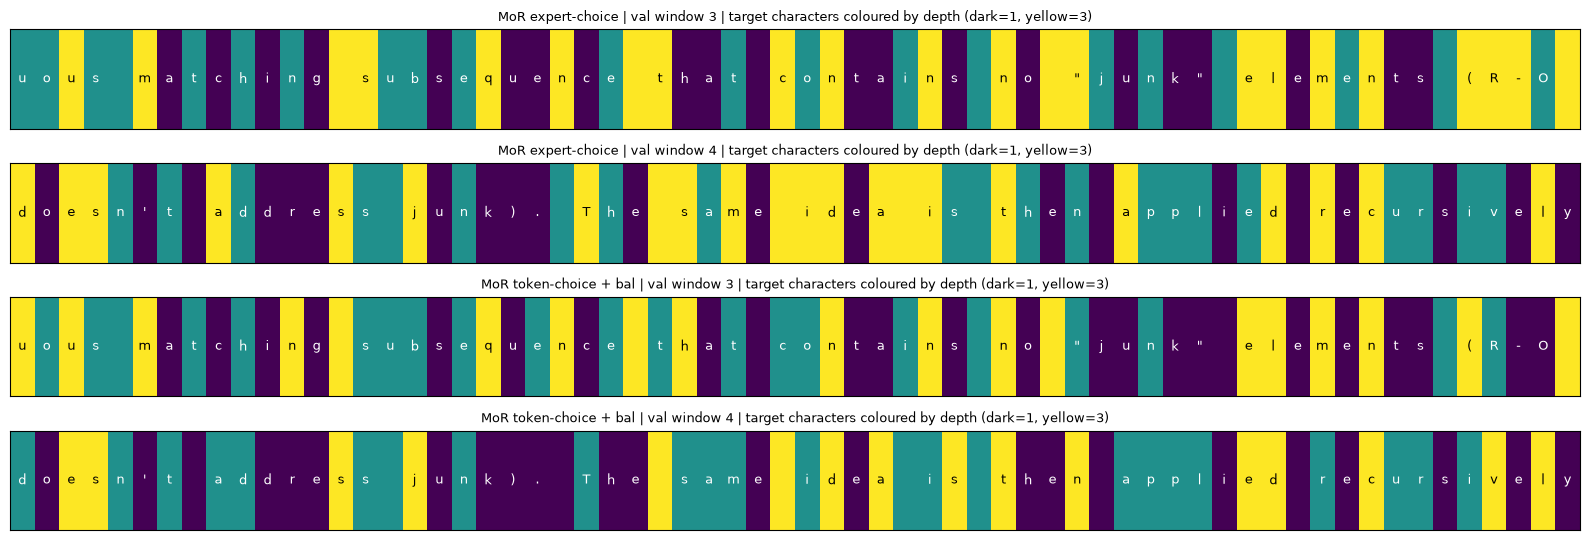

In [19]:
show_windows = [3, 4]
fig, axes = plt.subplots(4, 1, figsize=(16, 5.5))
panel = 0
for name in ["MoR expert-choice", "MoR token-choice + bal"]:
    model = doc_models[name].eval()
    with torch.no_grad():
        _, info = model(val_x[show_windows])
    model.train()
    for row, w in enumerate(show_windows):
        ax = axes[panel]
        depth = info["depth"][row].numpy()
        text = tok.decode(val_y[w])
        ax.imshow(depth[None], cmap="viridis", vmin=1, vmax=3, aspect="auto")
        for c, ch in enumerate(text):
            ax.text(c, 0, ch, ha="center", va="center", fontsize=9, color="white" if depth[c] < 2.5 else "black")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"{name} | val window {w} | target characters coloured by depth (dark=1, yellow=3)", fontsize=9)
        panel += 1
plt.tight_layout()
plt.show()

In [20]:
judge = doc_models["looped T=3 (full)"].eval()
with torch.no_grad():
    judge_logits, _ = judge(val_x)
    judge_ce = F.cross_entropy(judge_logits.reshape(-1, V), val_y.reshape(-1), reduction="none").reshape(val_y.shape)
judge.train()

for name in ["MoR expert-choice", "MoR token-choice + bal"]:
    model = doc_models[name].eval()
    with torch.no_grad():
        _, info = model(val_x)
    model.train()
    depth = info["depth"]
    print(f"\n{name}")
    for k in (1, 2, 3):
        mask = depth == k
        if mask.sum() == 0:
            print(f"  depth {k}: no tokens")
            continue
        chars = val_y[mask]
        counts = torch.bincount(chars, minlength=V)
        top = counts.topk(5).indices.tolist()
        top_str = ", ".join(repr(tok.itos[i]) for i in top)
        print(f"  depth {k}: {mask.float().mean():5.1%} of chars | judge loss {judge_ce[mask].mean() / math.log(2):.2f} bits"
              f" | most common targets: {top_str}")
    # by position: expert choice competes inside each window, so position may matter
    by_pos = depth.float().mean(0)
    print(f"  mean depth at positions 0-7: {by_pos[:8].mean():.2f}, positions 56-63: {by_pos[-8:].mean():.2f}")


MoR expert-choice
  depth 1: 32.8% of chars | judge loss 2.45 bits | most common targets: ' ', 'e', 'i', 'a', 'o'
  depth 2: 32.8% of chars | judge loss 2.64 bits | most common targets: ' ', 'e', 'n', 't', 'r'
  depth 3: 34.4% of chars | judge loss 3.93 bits | most common targets: 't', ' ', 'n', 's', 'r'
  mean depth at positions 0-7: 2.02, positions 56-63: 2.01



MoR token-choice + bal
  depth 1: 41.7% of chars | judge loss 2.62 bits | most common targets: ' ', 'e', 'i', 'a', 'o'
  depth 2: 32.7% of chars | judge loss 3.60 bits | most common targets: 't', ' ', 'e', 'l', 's'
  depth 3: 25.6% of chars | judge loss 2.93 bits | most common targets: ' ', 'n', 's', 'r', 't'
  mean depth at positions 0-7: 1.86, positions 56-63: 1.84


TODO_CONCL_DOCINSIDE

## 8. Experiments

### Experiment 1: compute vs quality at matched parameters
Validation bpc on the fixed validation set (all 223 non-overlapping 64-character windows, 14,272 scored characters). "Shared passes" is the measured fraction of $T\cdot N$ shared-block token-passes (1.00 = every token through all 3 passes). For expert-choice we evaluate with the leaky top-k rule **and** with the causal threshold rule that you would actually use for generation.

In [21]:
results = []
for name, model in doc_models.items():
    modes = ["topk", "threshold"] if model.routing == "expert" else ["topk"]
    for mode in modes:
        ev = evaluate(model, val_x, val_y, mode=mode)
        label = name if model.routing != "expert" else f"{name} [{'top-k, leaky' if mode == 'topk' else 'threshold, causal'}]"
        shared_vs_full3 = ev["mean_depth"] / 3                       # always relative to T=3 full
        results.append({"model": label, "params": n_params(model), "bpc": ev["bpc"],
                        "shared_passes": shared_vs_full3, "block_passes": 2 + ev["mean_depth"],
                        "train_s": doc_hist[name]["seconds"], "hist": ev["depth_hist"]})

print(f"{'model':48s} {'params':>7s} {'val bpc':>8s} {'shared passes':>14s} {'blocks/token':>13s} {'train s':>8s}")
for r in results:
    print(f"{r['model']:48s} {r['params']:7,d} {r['bpc']:8.3f} {r['shared_passes']:14.2f} {r['block_passes']:13.2f} {r['train_s']:8.1f}")
bpc = {r["model"]: r["bpc"] for r in results}

model                                             params  val bpc  shared passes  blocks/token  train s
looped T=3 (full)                                166,947    3.019           1.00          5.00    105.2
looped T=2 (full)                                166,947    3.045           0.67          4.00    144.4
MoR expert-choice [top-k, leaky]                 167,142    3.081           0.67          4.02    193.4
MoR expert-choice [threshold, causal]            167,142    3.081           0.66          3.99    193.4
MoR token-choice + bal                           167,142    3.050           0.61          3.84    187.1
MoR token-choice, no bal                         167,142    3.070           0.41          3.24    197.6


In [22]:
# agreement between the leaky top-k routing and the causal threshold routing of the same EC model
ec = doc_models["MoR expert-choice"].eval()
with torch.no_grad():
    _, info_topk = ec(val_x, mode="topk")
    _, info_thr = ec(val_x, mode="threshold")
ec.train()
agree = (info_topk["depth"] == info_thr["depth"]).float().mean().item()
print(f"same depth under top-k and threshold routing: {agree:.1%} of tokens")
print("depth histogram (0,1,2,3) top-k    :", np.round(torch.bincount(info_topk['depth'].flatten(), minlength=4).numpy() / info_topk['depth'].numel(), 3))
print("depth histogram (0,1,2,3) threshold:", np.round(torch.bincount(info_thr['depth'].flatten(), minlength=4).numpy() / info_thr['depth'].numel(), 3))

same depth under top-k and threshold routing: 92.7% of tokens
depth histogram (0,1,2,3) top-k    : [0.    0.328 0.328 0.344]
depth histogram (0,1,2,3) threshold: [0.    0.341 0.329 0.33 ]


TODO_CONCL_EXP1

### Experiment 2: load balancing for token-choice
Same model, same data, same seed. The only difference is $\lambda_{\text{bal}} = 0.1$ vs $0$.

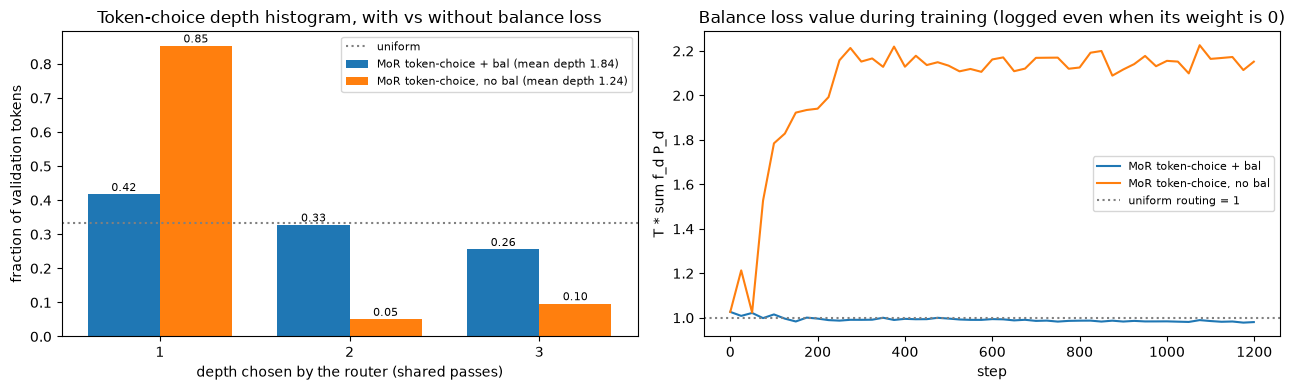

MoR token-choice + bal     mean router prob per depth [0.295 0.309 0.395] | mean max prob 0.793
MoR token-choice, no bal   mean router prob per depth [0.834 0.057 0.109] | mean max prob 0.978


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
width = 0.38
depths = np.arange(1, 4)
for offset, name in [(-width / 2, "MoR token-choice + bal"), (width / 2, "MoR token-choice, no bal")]:
    ev = evaluate(doc_models[name], val_x, val_y)
    axes[0].bar(depths + offset, ev["depth_hist"][1:], width=width, label=f"{name} (mean depth {ev['mean_depth']:.2f})")
    for dd, frac in zip(depths, ev["depth_hist"][1:]):
        axes[0].text(dd + offset, frac + 0.01, f"{frac:.2f}", ha="center", fontsize=8)
    axes[1].plot(doc_hist[name]["step"], doc_hist[name]["balance"], label=name)
axes[0].axhline(1 / 3, color="gray", ls=":", label="uniform")
axes[0].set_xticks(depths)
axes[0].set_xlabel("depth chosen by the router (shared passes)")
axes[0].set_ylabel("fraction of validation tokens")
axes[0].set_title("Token-choice depth histogram, with vs without balance loss")
axes[0].legend(fontsize=8)
axes[1].axhline(1.0, color="gray", ls=":", label="uniform routing = 1")
axes[1].set_xlabel("step")
axes[1].set_ylabel("T * sum f_d P_d")
axes[1].set_title("Balance loss value during training (logged even when its weight is 0)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for name in ["MoR token-choice + bal", "MoR token-choice, no bal"]:
    probs = doc_models[name].router(doc_models[name].prelude(
        doc_models[name].tok_emb(val_x[:64]) + doc_models[name].pos_emb(torch.arange(CTX)), causal_mask(CTX))).softmax(-1)
    print(f"{name:26s} mean router prob per depth {np.round(probs.mean((0, 1)).detach().numpy(), 3)} | "
          f"mean max prob {probs.max(-1).values.mean():.3f}")

TODO_CONCL_EXP2

### Experiment 3: measuring the causality leak
For 128 validation windows we change the character at position 40 (swap `e` and `t`, or set it to `e`) and check whether **any logit at positions 0..39** changed. In a correct causal LM the answer must be "never". We also count windows where the *routing* (depth) of an earlier token changed.

In [24]:
@torch.no_grad()
def leak_test(model: LoopedLM, mode: str, n_windows: int = 128, pos: int = 40) -> dict:
    model.eval()
    x_a = val_x[:n_windows]
    x_b = x_a.clone()
    e_id, t_id = tok.stoi["e"], tok.stoi["t"]
    x_b[:, pos] = torch.where(x_a[:, pos] == e_id, torch.full_like(x_a[:, pos], t_id), torch.full_like(x_a[:, pos], e_id))
    logits_a, info_a = model(x_a, mode=mode)
    logits_b, info_b = model(x_b, mode=mode)
    model.train()
    logit_diff = (logits_a[:, :pos] - logits_b[:, :pos]).abs().amax(dim=(1, 2))      # per window
    depth_changed = (info_a["depth"][:, :pos] != info_b["depth"][:, :pos]).any(dim=1)
    return {"windows_logits_changed": (logit_diff > 1e-5).float().mean().item(),
            "max_logit_diff": logit_diff.max().item(),
            "windows_routing_changed": depth_changed.float().mean().item()}


leak_rows = [("looped T=3 (full)", "topk"), ("MoR expert-choice", "topk"),
             ("MoR expert-choice", "threshold"), ("MoR token-choice + bal", "topk")]
leaks = {}
print(f"{'model / routing rule':42s} {'windows w/ earlier logits changed':>34s} {'max |diff|':>11s} {'routing changed':>16s}")
for name, mode in leak_rows:
    r = leak_test(doc_models[name], mode)
    label = f"{name} ({mode})" if doc_models[name].routing == "expert" else name
    leaks[label] = r
    print(f"{label:42s} {r['windows_logits_changed']:34.1%} {r['max_logit_diff']:11.2e} {r['windows_routing_changed']:16.1%}")

assert leaks["MoR expert-choice (topk)"]["windows_logits_changed"] > 0, "expected a leak from top-k"
assert leaks["MoR expert-choice (threshold)"]["max_logit_diff"] < 1e-5
assert leaks["MoR token-choice + bal"]["max_logit_diff"] < 1e-5
assert leaks["looped T=3 (full)"]["max_logit_diff"] < 1e-5
print("OK: top-k expert choice leaks future information; token choice and threshold routing do not")

model / routing rule                        windows w/ earlier logits changed  max |diff|  routing changed


looped T=3 (full)                                                        0.0%    0.00e+00             0.0%


MoR expert-choice (topk)                                                52.3%    2.86e+00            52.3%


MoR expert-choice (threshold)                                            0.0%    0.00e+00             0.0%


MoR token-choice + bal                                                   0.0%    0.00e+00             0.0%
OK: top-k expert choice leaks future information; token choice and threshold routing do not


TODO_CONCL_EXP3

### Experiment 4: does skipping tokens save wall-clock time?
The dense masked implementation still multiplies every token through the block (then throws away the unselected results), so it **cannot** be faster. The gather/scatter step only runs the block on the $k$ selected tokens. We time one recursion step of a $d=128$ block on $B=8$ sequences of length $L=512$ for several capacities (forward only, no gradient), then the whole trained expert-choice model on the validation set.

plain causal block on all 512 tokens: 51.4 ms
capacity     k  dense masked ms  gather ms  gather speed-up vs plain
   1.000   512             63.1       64.1                     0.80x
   0.500   256             52.4       21.9                     2.35x
   0.250   128             44.1        9.1                     5.63x
   0.125    64             44.4        5.5                     9.31x


looped T=3 (full)                      209.9 ms for 14,272 tokens
looped T=2 (full)                      166.5 ms for 14,272 tokens
MoR expert-choice, dense masked        219.8 ms for 14,272 tokens
MoR expert-choice, gather/scatter      183.2 ms for 14,272 tokens


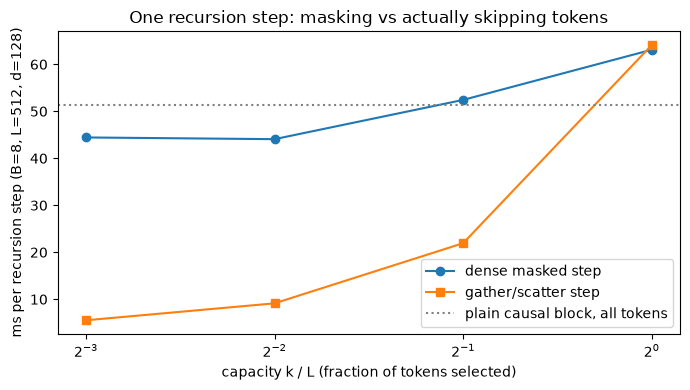

In [25]:
@torch.no_grad()
def time_ms(fn, reps: int = 5) -> float:
    fn()                                                  # warm-up
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1000


set_seed(5)
bench_block = Block(128, 4).eval()
B_b, L_b = 8, 512
h_b = torch.randn(B_b, L_b, 128)
scores_b = torch.randn(B_b, L_b)
gate_b = torch.sigmoid(scores_b)
all_active = torch.ones(B_b, L_b, dtype=torch.bool)
t_full = time_ms(lambda: bench_block(h_b, causal_mask(L_b)))
bench = []
for cap in [1.0, 0.5, 0.25, 0.125]:
    k = int(cap * L_b)
    sel, idx = expert_choice_select(scores_b, all_active, k)
    with torch.no_grad():
        diff = (recursion_step_dense(bench_block, h_b, sel, gate_b, 4) - recursion_step_gather(bench_block, h_b, idx, gate_b)).abs().max().item()
    assert diff < 1e-4
    t_dense = time_ms(lambda: recursion_step_dense(bench_block, h_b, sel, gate_b, 4))
    t_gather = time_ms(lambda: recursion_step_gather(bench_block, h_b, idx, gate_b))
    bench.append((cap, k, t_dense, t_gather))
print(f"plain causal block on all {L_b} tokens: {t_full:.1f} ms")
print(f"{'capacity':>8s} {'k':>5s} {'dense masked ms':>16s} {'gather ms':>10s} {'gather speed-up vs plain':>25s}")
for cap, k, td, tg in bench:
    print(f"{cap:8.3f} {k:5d} {td:16.1f} {tg:10.1f} {t_full / tg:24.2f}x")

# the trained docstring models, whole validation set, forward only
ec = doc_models["MoR expert-choice"].eval()
full3 = doc_models["looped T=3 (full)"].eval()
full2 = doc_models["looped T=2 (full)"].eval()
model_times = {
    "looped T=3 (full)": time_ms(lambda: full3(val_x)),
    "looped T=2 (full)": time_ms(lambda: full2(val_x)),
    "MoR expert-choice, dense masked": time_ms(lambda: ec(val_x, impl="dense")),
    "MoR expert-choice, gather/scatter": time_ms(lambda: ec(val_x, impl="gather")),
}
for m_ in (ec, full3, full2):
    m_.train()
for k_, v_ in model_times.items():
    print(f"{k_:36s} {v_:7.1f} ms for {val_x.numel():,} tokens")

fig, ax = plt.subplots(figsize=(7, 4))
caps = [b[0] for b in bench]
ax.plot(caps, [b[2] for b in bench], "o-", label="dense masked step")
ax.plot(caps, [b[3] for b in bench], "s-", label="gather/scatter step")
ax.axhline(t_full, color="gray", ls=":", label="plain causal block, all tokens")
ax.set_xscale("log", base=2)
ax.set_xlabel("capacity k / L (fraction of tokens selected)")
ax.set_ylabel("ms per recursion step (B=8, L=512, d=128)")
ax.set_title("One recursion step: masking vs actually skipping tokens")
ax.legend()
plt.tight_layout()
plt.show()

TODO_CONCL_EXP4

TODO_PITFALLS

TODO_RECAP

In [26]:
total = time.time() - NOTEBOOK_START
print(f"total notebook runtime: {total / 60:.1f} min")

total notebook runtime: 14.6 min
